# Ejercicio: **Mercados Financieros (Algoritmo No Supervisado)**

## **CONTEXTO TEÓRICO **

## Aprendizaje Supervisado vs. No Supervisado: ¿Cuándo Usar Cada Uno?

La elección entre aprendizaje supervisado y no supervisado depende principalmente de la **estructura de los datos** y del **objetivo del problema**.

### Usa Aprendizaje Supervisado Cuando:
* **Tienes etiquetas históricas:** Tu conjunto de datos ya contiene resultados conocidos (por ejemplo, impagos de crédito pasados, retornos históricos de activos o casos de fraude etiquetados).
* **Quieres predecir un resultado específico:** Tu objetivo es pronosticar un número (**Regresión**) o asignar una categoría conocida (**Clasificación**).
* **Necesitas métricas claras de precisión:** Como existen respuestas verdaderas en tu conjunto de prueba, puedes medir objetivamente el rendimiento con métricas como R-cuadrado, Exactitud (Accuracy), Precisión o Exhaustividad (Recall).
* **Ejemplo:** Usar `Volatility`, `Beta` y `Momentum` para predecir si el `Annual_Return` de una acción el próximo año será positivo o negativo.

### Usa Aprendizaje No Supervisado Cuando:
* **Tus datos no están etiquetados:** Tienes variables de entrada, pero ninguna columna con la "respuesta correcta" histórica para entrenar (y etiquetar manualmente es muy costoso o imposible).
* **Tu objetivo es explorar y descubrir estructuras:** Quieres descubrir segmentos ocultos, comprimir conjuntos de datos complejos o detectar valores atípicos (outliers) sin reglas predefinidas.
* **Estás preparando datos para tareas posteriores:** Técnicas no supervisadas como el Análisis de Componentes Principales (PCA) permiten reducir docenas de variables correlacionadas en unas pocas características limpias antes de alimentar un modelo supervisado.
* **Ejemplo:** Agrupar 500 acciones en clústeres naturales según su perfil de riesgo usando `Volatility` y `Max_Drawdown`, sin indicarle de antemano al algoritmo cuántos niveles de riesgo existen.

---

### Matriz Rápida de Decisión

| Criterio | Aprendizaje Supervisado | Aprendizaje No Supervisado |
| :--- | :--- | :--- |
| **Variable Objetivo ($y$)** | Presente y conocida | Ausente o desconocida |
| **Objetivo Principal** | Predicción y pronóstico | Descubrimiento de patrones y agrupación |
| **Esfuerzo Humano Inicial** | Alto (requiere datos etiquetados limpios) | Bajo (trabaja directo con variables crudas) |
| **Evaluación** | Comparación directa contra la verdad real | Indirecta (cohesión de clústeres, revisión experta) |

---

---

## El Flujo de Trabajo Estándar en Machine Learning (VISTA GENERAL)

Construir un modelo de ML sigue un proceso iterativo y repetible desde los datos sin procesar hasta su despliegue en el mundo real.


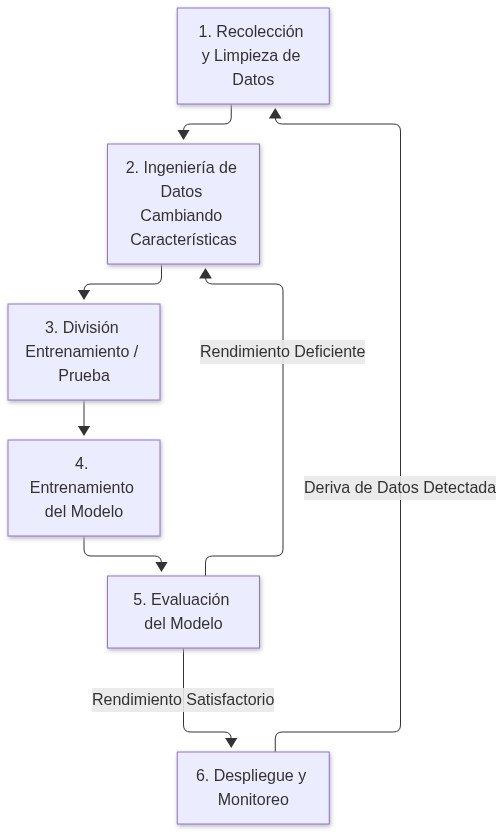

### Desglose Paso a Paso
* **1. Recolección y Limpieza de Datos:** Reunir datos crudos y corregir valores faltantes, duplicados o valores atípicos. Tener datos limpios importa mucho más que usar algoritmos complejos.
* **2. Ingeniería de Características (Feature Engineering):** Seleccionar y transformar variables crudas (como convertir precios diarios en `Volatility` o `Momentum`) para que el modelo detecte patrones con mayor facilidad.
* **3. División Entrenamiento / Prueba (Train/Test Split):** Dividir los datos en un conjunto de entrenamiento (usualmente 70–80%) para enseñar al modelo, y un conjunto de prueba (20–30%) para evaluarlo con datos no vistos sin fuga de información.
* **4. Entrenamiento del Modelo:** Alimentar un algoritmo (como Regresión Lineal, Random Forest o Redes Neuronales) con los datos de entrenamiento para encontrar los parámetros matemáticos óptimos.
* **5. Evaluación del Modelo:** Medir la precisión en el conjunto de prueba usando métricas adecuadas para la tarea, como el Error Cuadrático Medio para regresión o Precisión y Recall para clasificación. Si el rendimiento es bajo, se regresa a la Ingeniería de Características o se ajustan los hiperparámetros.
* **6. Despliegue y Monitoreo:** Poner el modelo en producción y supervisarlo a lo largo del tiempo para detectar pérdida de rendimiento conforme cambian los datos del mundo real.


## **CASO PRÁCTICO: ALGORITMO NO SUPERVISADO (K-MEANS)**
---
Haremos un ejercicio de agrupamiento con una colección de acciones de NASDAQ. Con cinco métricas que miden el **rendimiento, el riesgo y el comportamiento del precio** de un activo financiero o portafolio. En conjunto, ayudan a los inversionistas a evaluar cuánto genera una inversión frente a qué tan volátil o riesgoso es el camino para obtener esos rendimientos.

---

## 1. Retorno Anual (`Annual_Return`)
* **Qué es:** El porcentaje de ganancia o pérdida que genera una inversión durante un período de un año.
* **Cómo funciona:** Cuando se mide a lo largo de varios años, suele expresarse como la Tasa de Crecimiento Anual Compuesta (CAGR, por sus siglas en inglés), la cual considera los efectos del interés compuesto año tras año.
* **Por qué importa:** Proporciona una base estandarizada para comparar diferentes inversiones (como acciones, bonos o bienes raíces) exactamente en el mismo marco de tiempo.

## 2. Volatilidad (`Volatility`)
* **Qué es:** Una medida estadística de qué tanto oscila el precio de un activo alrededor de su promedio a lo largo del tiempo, calculada normalmente como la desviación estándar anualizada de los rendimientos diarios o mensuales.
* **Cómo funciona:** Una volatilidad alta significa que el precio sube y baja drásticamente en períodos cortos. Una volatilidad baja significa que el precio se mueve de manera estable y predecible.
* **Por qué importa:** La volatilidad es la medida principal del riesgo total individual, ayudándote a comprender cuánta turbulencia diaria debes esperar.

## 3. Beta (`Beta`)
* **Qué es:** Una medida de la sensibilidad y volatilidad de un activo en relación con el mercado en general (como el índice S&P 500, que tiene una Beta base de **1.0**).
* **Cómo funciona:** Una Beta superior a **1.0** (por ejemplo, 1.3) indica que el activo tiende a moverse un 30% más que el mercado en cualquiera de las dos direcciones. Una Beta inferior a **1.0** (por ejemplo, 0.7) indica que se mueve menos que el mercado, mientras que una Beta negativa significa que tiende a moverse en la dirección opuesta.
* **Por qué importa:** La Beta mide el riesgo sistemático de mercado, mostrando qué tanto amplificará o amortiguará un activo tu portafolio durante las alzas y caídas generales del mercado.

## 4. Momentum (`Momentum`)
* **Qué es:** La tasa de aceleración del precio de un activo, la cual mide la fuerza y persistencia de su tendencia reciente al alza o a la baja.
* **Cómo funciona:** Se calcula comúnmente comparando el precio actual con el precio de un período determinado en el pasado (como hace 3, 6 o 12 meses).
* **Por qué importa:** El Momentum se basa en la tendencia del mercado de que los activos con buen desempeño en el pasado reciente suelen seguir rindiendo bien a corto plazo, y viceversa.

## 5. Máxima Caída (`Max_Drawdown`)
* **Qué es:** La mayor caída porcentual individual desde un pico histórico hasta un punto mínimo posterior antes de alcanzar un nuevo pico.
* **Cómo funciona:** Si una acción sube a $100, cae a $60 y luego se recupera hasta $110, su Máxima Caída para ese período es de **-40%**.
* **Por qué importa:** A diferencia de la volatilidad (que trata por igual las oscilaciones al alza y a la baja), la Máxima Caída se enfoca estrictamente en el peor escenario de riesgo a la baja y muestra cuánto capital podrías perder si compraras en el peor momento posible.


---

## Tabla Comparativa Rápida

| Métrica | Enfoque Principal | Qué Significa un Valor Alto |
| :--- | :--- | :--- |
| **Retorno Anual** | Recompensa / Crecimiento | Fuertes ganancias históricas anuales |
| **Volatilidad** | Riesgo Individual | Oscilaciones de precio amplias e impredecibles |
| **Beta** | Sensibilidad al Mercado | Amplifica las subidas y bajadas del mercado general |
| **Momentum** | Fuerza de la Tendencia | Fuerte movimiento alcista reciente del precio |
| **Máxima Caída** | Pérdida en el Peor Escenario | Severo desplome histórico de pico a fondo |


In [20]:
import urllib.request
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import itertools

# =====================================================================
# CONFIGURACIÓN Y CONSTANTES
# =====================================================================
FECHA_INICIO = "2024-01-01"
FECHA_FIN = "2026-11-01"
K_OPTIMO = 4
TAMANO_MUESTRA = 150  # Salvaguarda para evitar bloqueos por parte de Yahoo Finance

In [21]:
def obtener_tickers_nasdaq():
    """Descarga el directorio oficial en vivo de las acciones listadas en NASDAQ."""
    print("📥 Paso 1: Descargando el directorio completo y en vivo de tickers de NASDAQ...")
    nasdaq_url = "https://www.nasdaqtrader.com/dynamic/symdir/nasdaqlisted.txt"

    req = urllib.request.Request(nasdaq_url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as response:
        nasdaq_raw = pd.read_csv(response, sep="|")

    nasdaq_raw = nasdaq_raw.iloc[:-1]  # Elimina el pie de página con la marca de tiempo
    tickers_completos = nasdaq_raw['Symbol'].dropna().unique().tolist()
    print(f"✅ ¡Éxito! Se encontraron {len(tickers_completos)} listados activos en la bolsa.")
    return tickers_completos

In [22]:
def descargar_datos_historicos(tickers, tamano_muestra):
    """Descarga los precios históricos y realiza la limpieza inicial de datos."""
    universo_muestra = [t.replace('.', '-') for t in tickers[:tamano_muestra]]
    lista_descarga = universo_muestra + ['^GSPC']

    print(f"\n📥 Paso 2: Extrayendo matriz de datos históricos para {tamano_muestra} acciones...")
    datos_raw = yf.download(lista_descarga, start=FECHA_INICIO, end=FECHA_FIN, threads=True)
    precios_cierre = datos_raw['Close']

    precios_acciones = precios_cierre[universo_muestra]
    precios_mercado = precios_cierre['^GSPC']

    # Limpieza: Filtrar acciones que tengan más del 5% de datos faltantes
    umbral_faltantes = 0.05 * len(precios_cierre)
    precios_acciones = precios_acciones.dropna(thresh=len(precios_cierre) - umbral_faltantes, axis=1)
    tickers_activos = precios_acciones.columns.tolist()

    retornos_acciones = precios_acciones.pct_change().dropna()
    retornos_mercado = precios_mercado.pct_change().dropna()

    return precios_acciones, retornos_acciones, retornos_mercado, tickers_activos

In [23]:
def calcular_caracteristicas(precios_acciones, retornos_acciones, retornos_mercado, tickers_activos):
    """Calcula las 5 métricas de comportamiento financiero para el clustering."""
    print("⚙️ Paso 3: Calculando las 5 características conductuales...")
    df_features = pd.DataFrame(index=tickers_activos)

    # 1. Rendimiento Anualizado
    df_features['Retorno_Anual'] = retornos_acciones.mean() * 252

    # 2. Volatilidad Anualizada
    df_features['Volatilidad'] = retornos_acciones.std() * np.sqrt(252)

    # 3. Beta de Mercado
    varianza_mercado = retornos_mercado.var()
    df_features['Beta'] = [retornos_acciones[t].cov(retornos_mercado) / varianza_mercado for t in tickers_activos]

    # 4. Momentum Estructural
    df_features['Momentum'] = (precios_acciones.iloc[-1] / precios_acciones.iloc[0]) - 1

    # 5. Máximo Drawdown (Peor caída pico a valle)
    lista_max_dd = []
    for t in tickers_activos:
        indice_riqueza = (1 + retornos_acciones[t]).cumprod()
        lista_max_dd.append(((indice_riqueza - indice_riqueza.cummax()) / indice_riqueza.cummax()).min())
    df_features['Max_Drawdown'] = lista_max_dd

    df_features = df_features.replace([np.inf, -np.inf], np.nan).dropna()
    return df_features

In [24]:
def graficar_metodo_codo(scaled_features):
    """Calcula e imprime el gráfico de optimización para el método del codo."""
    print("\n📊 Calculando optimización de clústeres (Método del Codo)...")
    wcss = []
    rango_k = range(1, 10)
    for k in rango_k:
        kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init='auto')
        kmeans.fit(scaled_features)
        wcss.append(kmeans.inertia_)

    plt.figure(figsize=(8, 4.5))
    plt.plot(rango_k, wcss, marker='s', linestyle='-', color='indigo', linewidth=2)
    plt.title('Método del Codo: Optimización de Clústeres en NASDAQ', fontweight='bold')
    plt.xlabel('Número de Clústeres (K)')
    plt.ylabel('Inercia / WCSS')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

In [25]:
def graficar_proyecciones_2d(df_features):
    """Genera una cuadrícula de gráficos combinando las características en pares 2D."""
    columnas_features = ['Retorno_Anual', 'Volatilidad', 'Beta', 'Momentum', 'Max_Drawdown']
    pares_features = list(itertools.combinations(columnas_features, 2))

    fig, axes = plt.subplots(5, 2, figsize=(14, 22))
    axes = axes.flatten()

    for i, (col_x, col_y) in enumerate(pares_features):
        ax = axes[i]

        # Puntos coloreados según la etiqueta global de su clúster
        scatter = ax.scatter(df_features[col_x], df_features[col_y],
                             c=df_features['Cluster'], cmap='plasma', s=150, alpha=0.8, edgecolors='black')

        # Añadir etiquetas de texto con los tickers de las acciones
        for ticker in df_features.index:
            ax.annotate(ticker, (df_features.loc[ticker, col_x], df_features.loc[ticker, col_y]),
                        textcoords="offset points", xytext=(0, 6), ha='center', fontsize=9, fontweight='semibold')

        ax.set_title(f'{col_y} vs {col_x}', fontsize=11, fontweight='bold')
        ax.set_xlabel(col_x)
        ax.set_ylabel(col_y)
        ax.grid(True, linestyle=':', alpha=0.6)

    for j in range(len(pares_features), len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle('Clústeres de Acciones Mostrados en Proyecciones Combinadas 2D', fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.show()

In [26]:
# =====================================================================
# Fase 1: Extracción del listado de la bolsa
# =====================================================================
tickers_completos = obtener_tickers_nasdaq()

📥 Paso 1: Descargando el directorio completo y en vivo de tickers de NASDAQ...
✅ ¡Éxito! Se encontraron 5605 listados activos en la bolsa.


In [27]:
# =====================================================================
# Fase 2: Descarga de precios
# =====================================================================
p_acciones, r_acciones, r_mercado, tickers_filtrados = descargar_datos_historicos(tickers_completos, TAMANO_MUESTRA)

/tmp/ipykernel_1144/127467486.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos_raw = yf.download(lista_descarga, start=FECHA_INICIO, end=FECHA_FIN, threads=True)
[                       0%                       ]


📥 Paso 2: Extrayendo matriz de datos históricos para 150 acciones...


[*********************100%***********************]  151 of 151 completed
ERROR:yfinance:
15 Failed downloads:
ERROR:yfinance:['ABLVW', 'ACONW', 'AACIW', 'AERTW', 'ACAAW', 'AFJKR', 'AACPW', 'AEAQW', 'ADSEW', 'AENTW', 'AESPW', 'AACOW', 'AESPR', 'ADACW']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-01-01 -> 2026-11-01)')
ERROR:yfinance:['ACEM']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-01-01 -> 2026-11-01) (Yahoo error = "Data doesn\'t exist for startDate = 1704085200, endDate = 1793505600")')


In [28]:
# =====================================================================
# Fase 3: Procesamiento de datos y métricas financieras
# =====================================================================
features_df = calcular_caracteristicas(p_acciones, r_acciones, r_mercado, tickers_filtrados)

⚙️ Paso 3: Calculando las 5 características conductuales...


In [29]:
# =====================================================================
# Fase 4: Escalado estándar Z-Score
# =====================================================================
scaler = StandardScaler()
caracteristicas_escaladas = scaler.fit_transform(features_df)


📊 Calculando optimización de clústeres (Método del Codo)...


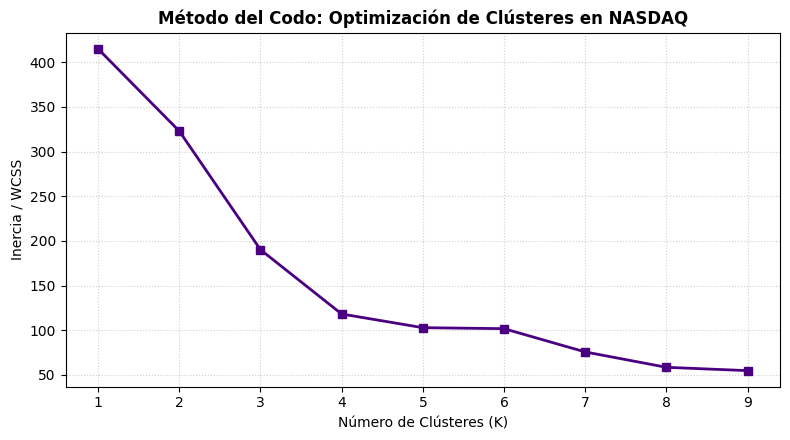

In [30]:
# =====================================================================
# Fase 5: Visualización del método del codo
# =====================================================================
graficar_metodo_codo(caracteristicas_escaladas)

In [31]:
# =====================================================================
# Fase 6: Entrenamiento y ajuste del modelo K-Means final (K = 4)
# =====================================================================
print(f"\n🎯 Ajustando modelo de clustering definitivo (K = {K_OPTIMO})...")
kmeans_final = KMeans(n_clusters=K_OPTIMO, init='k-means++', random_state=42, n_init='auto')
features_df['Cluster'] = kmeans_final.fit_predict(caracteristicas_escaladas)


🎯 Ajustando modelo de clustering definitivo (K = 4)...


In [33]:
# =============================================================================
# Fase 7: Filtrado del clúster con mejor desempeño (Filtro por Ratio de Sharpe)
# =============================================================================
rendimiento_clusters = features_df.groupby('Cluster').agg({
        'Retorno_Anual': 'mean',
        'Volatilidad': 'mean'
    })
rendimiento_clusters['Sharpe_Grupal'] = rendimiento_clusters['Retorno_Anual'] / rendimiento_clusters['Volatilidad']

id_mejor_cluster = rendimiento_clusters['Sharpe_Grupal'].idxmax()
acciones_elite = features_df[features_df['Cluster'] == id_mejor_cluster]

# Impresión de Resultados por Consola
print("\n" + "="*55)
print(f"🌟 CLÚSTER CON MEJOR RENDIMIENTO ENCONTRADO: Grupo {id_mejor_cluster}")
print(f"📊 Métricas Promedio del Clúster: Retorno: {rendimiento_clusters.loc[id_mejor_cluster, 'Retorno_Anual']:.2%}, Volatilidad: {rendimiento_clusters.loc[id_mejor_cluster, 'Volatilidad']:.2%}")
print(f"📋 Total de Tickers dentro de este Clúster: {len(acciones_elite)}")
print("="*55)

print("\n✨ Tickers (Símbolos) en el Clúster de Alto Rendimiento:")
print(acciones_elite.index.tolist())

print("\n🔎 Desglose Analítico Detallado del Clúster de Élite:")
print(acciones_elite.round(4))


🌟 CLÚSTER CON MEJOR RENDIMIENTO ENCONTRADO: Grupo 1
📊 Métricas Promedio del Clúster: Retorno: 82.52%, Volatilidad: 100.39%
📋 Total de Tickers dentro de este Clúster: 16

✨ Tickers (Símbolos) en el Clúster de Alto Rendimiento:
['AAOI', 'AAPB', 'AAPU', 'ABCL', 'ABSI', 'ABVX', 'ACFN', 'ACMR', 'ACRS', 'ADMA', 'ADPT', 'AEHR', 'AEIS', 'AENT', 'AEVA', 'AEYE']

🔎 Desglose Analítico Detallado del Clúster de Élite:
      Retorno_Anual  Volatilidad    Beta  Momentum  Max_Drawdown  Cluster
AAOI         1.3112       1.3025  4.0255    2.6945       -0.7717        1
AAPB         0.4135       0.5471  2.1135    1.2330       -0.5813        1
AAPU         0.4251       0.5392  2.1015    1.3130       -0.5861        1
ABCL         0.5613       0.7489  1.7222    1.1414       -0.6547        1
ABSI         0.8657       0.9723  2.5024    2.0163       -0.6606        1
ABVX         2.3867       3.5883  1.6721    7.0176       -0.6746        1
ACFN         0.6635       0.7649  0.6327    1.5579       -0.5811        


🖼️ Generando matriz de gráficos de dispersión multidimensionales...


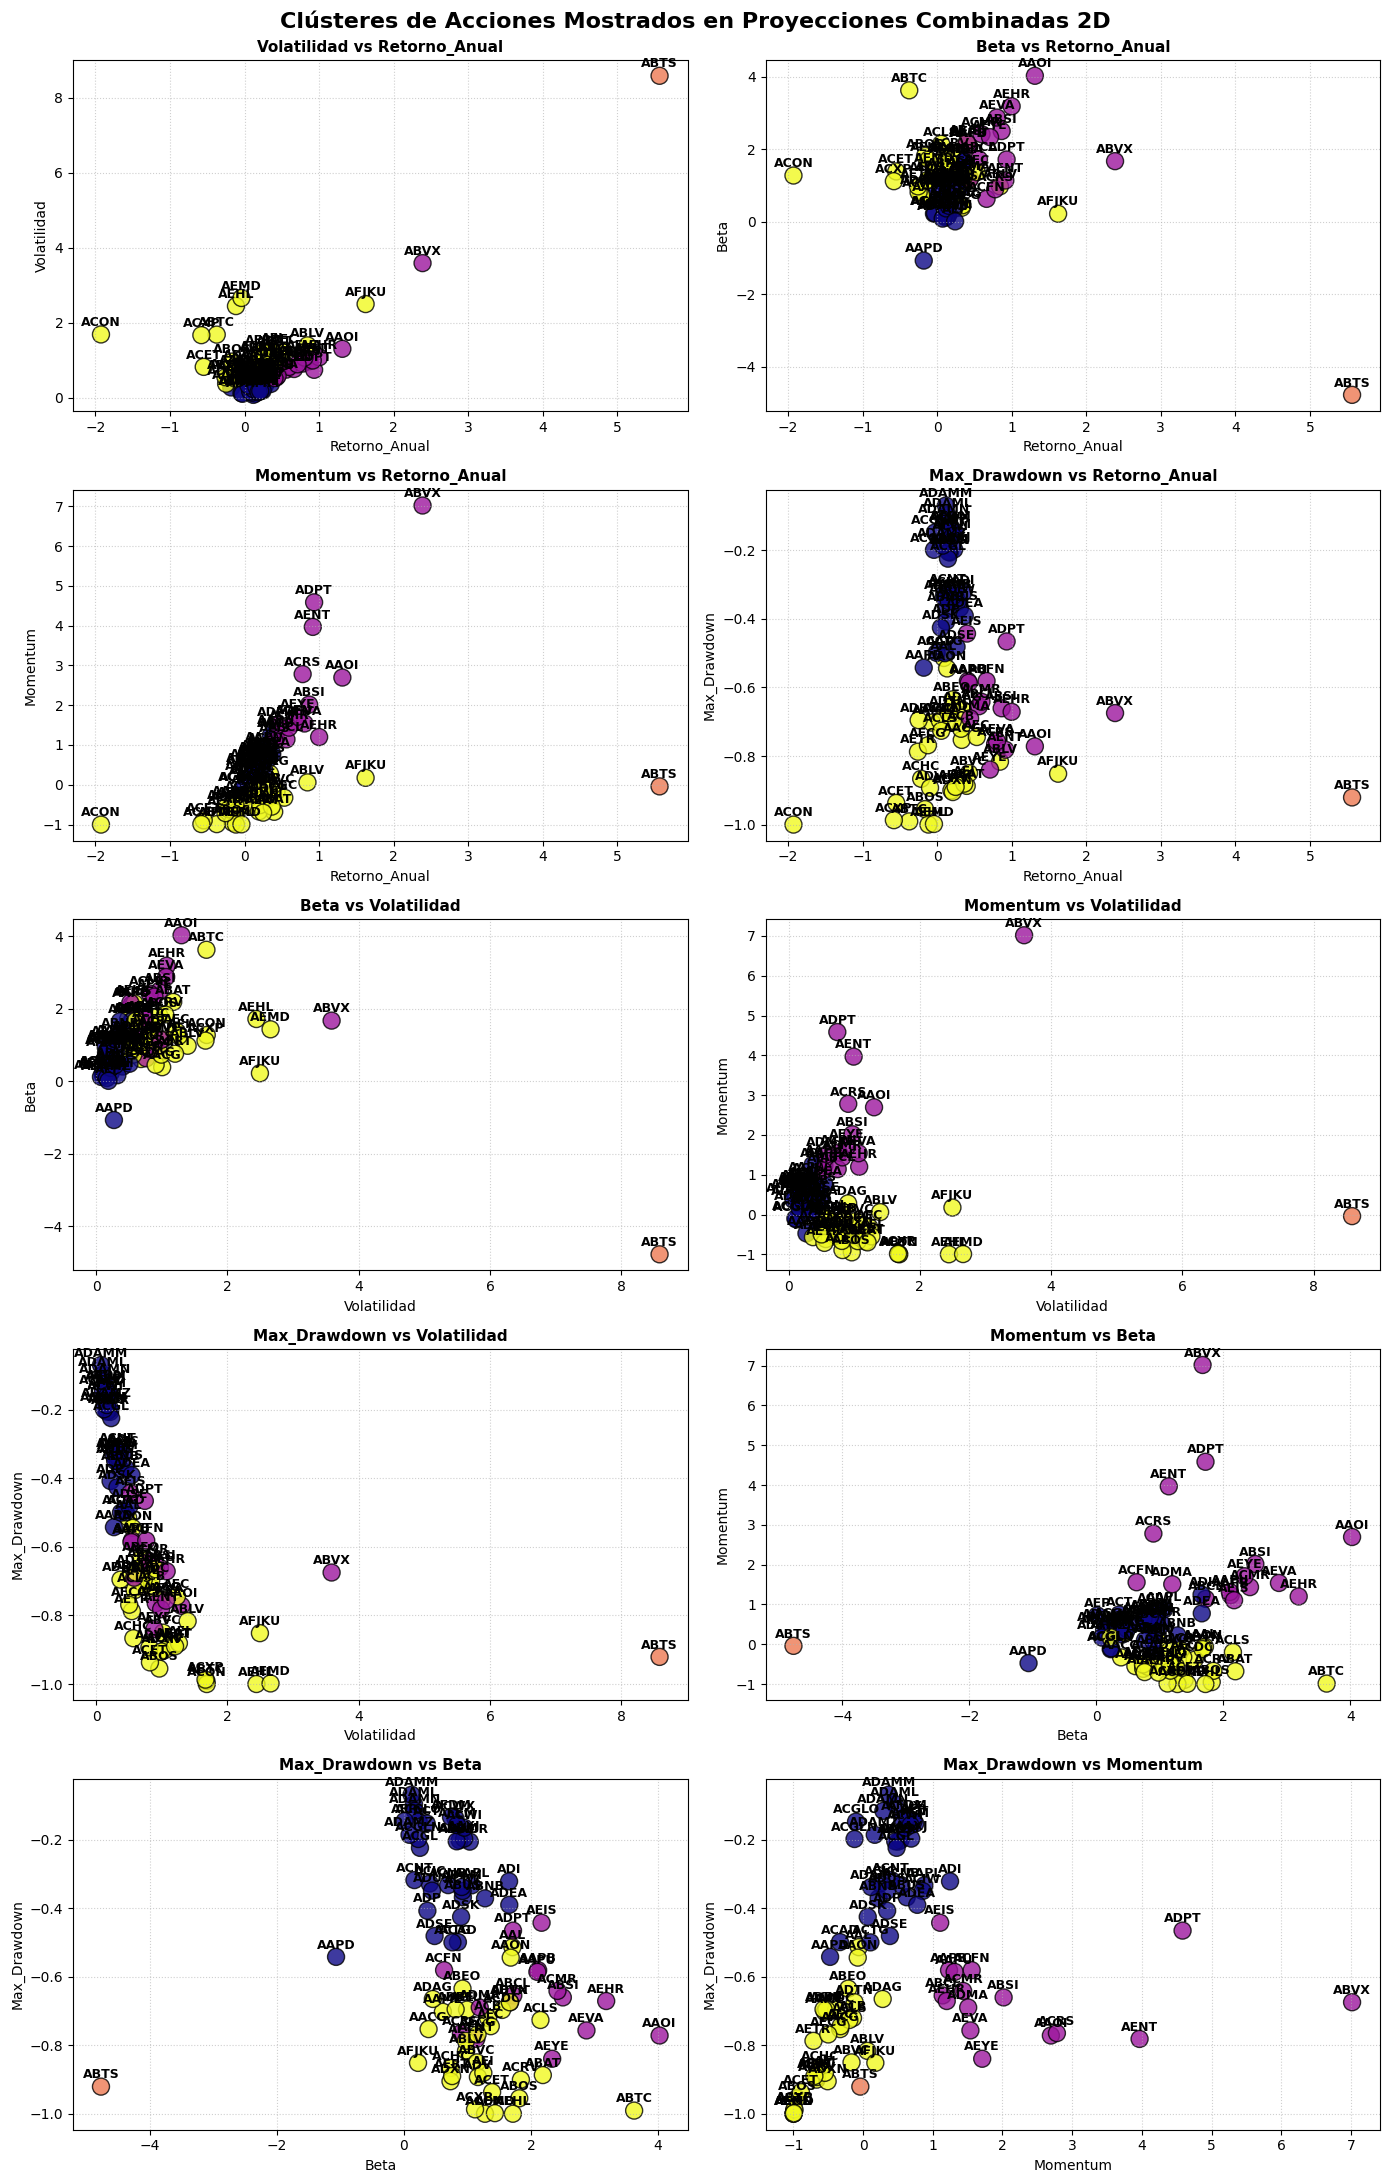

In [34]:
# =============================================================================
# Fase 8: Mostrar la matriz de gráficos combinados 2D
# =============================================================================
print("\n🖼️ Generando matriz de gráficos de dispersión multidimensionales...")
graficar_proyecciones_2d(features_df)
